# S=7 support sweep, part b of 2: Transformer AR vs causal encoder, 20,000 updates, sampled evaluation

Seven visible operation slots with `<identity>` fillers. The training support varies; the format, models and recipe
do not.

| condition | train k | held-out tests |
|---|---|---|
| S7_k02 | 0,2 | k=1 at every slot; k=3–7 |
| S7_k023 | 0,2,3 | k=1; k=4–7 |
| S7_k0234 | 0,2,3,4 | k=1; k=5–7 |
| S7_k02345 | 0,2,3,4,5 | k=1; k=6, 7 |
| S7_k023456 | 0,2,3,4,5,6 | k=1; k=7 |
| S7_k0234567 | 0,2,3,4,5,6,7 | k=1 only (k=7 fills every slot: trained zero-identity instructions) |

**Training.** 20,000 updates × 256 (5.12M examples).
* One common initialization per architecture: all conditions share capacity 7.
* Records at a common k are shared across conditions by index.

**Evaluation: the LAST checkpoint, on a SAMPLED test set** (about 50–100k records per run, instead of millions):
* Singletons: A/B/C × all 7 slots × 1000 grids = 21,000. Exhaustive.
* Each trained k: 5000 (word, grid) records.
* Each held-out longer k: 20,000 records. Words are cycled so each appears almost equally often.

The sizes are set in the config cell.

**This notebook = part b of 2: S7_k02345, S7_k023456, S7_k0234567.** The other half is notebook 23a, and the two can run at
the same time on two runtimes. They share one results folder, but each condition has its own subfolder, so they do
not interfere.

**Send back `S7_Sweep_20k_partb_Review.ipynb`.** After BOTH halves finish, the optional last cell (in either
notebook) produces `S7_Sweep_20k_ALL_Review.ipynb` with all 12 runs.


In [2]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: b1b6bb2bc78b3d6c842c09f8e34d8dc66babbaef


In [3]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
MODE = os.environ.get("DECOMP_MODE", "full")
SEED = 42
RUN_CONDITIONS = ['S7_k02345', 'S7_k023456', 'S7_k0234567']          # this half of the sweep (the other half runs in notebook 23a)
ALL_CONDITIONS = ["S7_k02", "S7_k023", "S7_k0234", "S7_k02345", "S7_k023456", "S7_k0234567"]
RUN_MODELS = ["transformer_ar", "causal_encoder"]
STEPS = 20000
SUBDIR = "S7_support_sweep_20k_v1"
EVAL_PLAN = {"n_single_grids": 1000, "n_seen_per_k": 5000, "n_long_per_k": 20000}
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import longk as LK, longk_exp as LX
_c = LX.make_cfg(RUN_CONDITIONS[0], RESULTS_ROOT, MODE, RUN_MODELS, SEED, SUBDIR,
                 **({"optimizer_steps": STEPS} if MODE == "full" else {}))
print("resolved recipe:", _c.train.semantic_dict())
print("results ->", LX.family_root(RESULTS_ROOT, MODE, SUBDIR))


Mounted at /content/drive
resolved recipe: {'seed': 42, 'optimizer_steps': 20000, 'effective_batch_size': 256, 'lr': 0.0003, 'min_lr': 3e-05, 'weight_decay': 0.01, 'betas': [0.9, 0.95], 'warmup_steps': 250, 'grad_clip': 1.0, 'val_every': 250}
results -> /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1


In [4]:
# --- Train (20,000 updates) + sampled LAST-checkpoint evaluation, sequentially (resumable) ---------------------------
status = LX.run_queue(RESULTS_ROOT, MODE, SEED, RUN_CONDITIONS, RUN_MODELS, repo_dir=str(REPO_DIR), device=DEVICE,
                      subdir=SUBDIR, steps=STEPS if MODE == "full" else None, sampled_plan=EVAL_PLAN)
display(status)


[S7_k02345] S=7 train k=[0, 2, 3, 4, 5] | val 1500 | manifests bdf24c327a65

=== S7_k02345 / transformer_ar ===
  microbatch probe: 256 fits
[transformer_ar] 10,703,636 params | device NVIDIA RTX PRO 6000 Blackwell Server Edition | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 1.5962 (best) | subset(160) exact 0.144 cell 0.360
  step 475/20000 loss 1.2117 lr 3.00e-04 | 23.66 steps/s, 6057 ex/s | ETA 13.8 min
  [val @ 500] cell CE 1.2094 (best) | subset(160) exact 0.212 cell 0.388
  [val @ 750] cell CE 0.9414 (best) | subset(160) exact 0.219 cell 0.443
  step 900/20000 loss 0.7236 lr 2.99e-04 | 22.46 steps/s, 5749 ex/s | ETA 14.2 min
  [val @ 1000] cell CE 0.6344 (best) | subset(160) exact 0.212 cell 0.541
  [val @ 1250] cell CE 0.3467 (best) | subset(160) exact 0.331 cell 0.671
  step 1375/20000 loss 0.2129 lr 2.98e-04 | 22.72 steps/s, 5817 ex/s | ETA 13.7 min
  [val @ 1500] cell CE 0.1082 (best) | subset(160) exact 0.631 cell 0.911
  [val @ 1750] cell CE 0.0

,condition,model,trained,evaluated_last,records,best_step (reference),complete
0,S7_k02345,transformer_ar,True,True,82000,20000,True
1,S7_k02345,causal_encoder,True,True,82000,19500,True
2,S7_k023456,transformer_ar,True,True,67000,19500,True
3,S7_k023456,causal_encoder,True,True,67000,20000,True
4,S7_k0234567,transformer_ar,True,True,52000,20000,True
5,S7_k0234567,causal_encoder,True,True,52000,19250,True


In [6]:
import numpy as np
from decompositionality import longk_exp as LX

def _load_eval_fixed(cfg, model_id):
    ed = LX.eval_dir(cfg, model_id)
    fs = sorted((ed / "chunks").glob("chunk_*.npz"))
    parts = [dict(np.load(f)) for f in fs]
    if not parts:
        return {}
    keys = [k for k in parts[0] if np.asarray(parts[0][k]).ndim > 0]   # skip scalar metadata (config_hash, plan)
    return {k: np.concatenate([p[k] for p in parts]) for k in keys}

LX.load_eval = _load_eval_fixed

# Transformer AR vs causal encoder — LAST checkpoint, singletons and longer instructions (seed 42)
6/6 runs complete. Every number below is for the model after the final update (not the validation-selected checkpoint). Budget: 20000 updates; sampled evaluation {'n_single_grids': 1000, 'n_seen_per_k': 5000, 'n_long_per_k': 20000}. Part b of 2.


### Run status


,condition,model,trained,evaluated_last,records,best_step (reference),complete
0,S7_k02345,transformer_ar,True,True,82000,20000,True
1,S7_k02345,causal_encoder,True,True,82000,19500,True
2,S7_k023456,transformer_ar,True,True,67000,19500,True
3,S7_k023456,causal_encoder,True,True,67000,20000,True
4,S7_k0234567,transformer_ar,True,True,52000,20000,True
5,S7_k0234567,causal_encoder,True,True,52000,19250,True



### Summary: singletons and longer held-out instructions (LAST checkpoint)


,condition,model,status,A,B,C,singletons,singleton cell acc,trained-k exact,k=6 exact,k=7 exact
0,S7_k02345,transformer_ar,available,0/7000,6941/7000,0/7000,6941/21000,0.4103,1.0000,271/20000 (0.014),47/20000 (0.002)
1,S7_k02345,causal_encoder,available,7000/7000,7000/7000,7000/7000,21000/21000,1.0000,1.0000,18990/20000 (0.950),9284/20000 (0.464)
2,S7_k023456,transformer_ar,available,7000/7000,6999/7000,2402/7000,16401/21000,0.8111,0.9999,NaN,7876/20000 (0.394)
3,S7_k023456,causal_encoder,available,7000/7000,7000/7000,7000/7000,21000/21000,1.0000,1.0000,NaN,20000/20000 (1.000)
4,S7_k0234567,transformer_ar,available,7000/7000,7000/7000,6994/7000,20994/21000,1.0000,1.0000,NaN,NaN
5,S7_k0234567,causal_encoder,available,7000/7000,7000/7000,7000/7000,21000/21000,1.0000,1.0000,NaN,NaN



### Exact / cell accuracy by k


... (4 outputs left out)

,condition,model,op,n,correct,identity copy,other legal transform,non-legal grid
0,S7_k02345,transformer_ar,A,7000,0,0,11,6989
1,S7_k02345,transformer_ar,B,7000,6941,0,0,59
2,S7_k02345,transformer_ar,C,7000,0,5589,0,1411
3,S7_k02345,causal_encoder,A,7000,7000,0,0,0
4,S7_k02345,causal_encoder,B,7000,7000,0,0,0
5,S7_k02345,causal_encoder,C,7000,7000,0,0,0
6,S7_k023456,transformer_ar,A,7000,7000,0,0,0
7,S7_k023456,transformer_ar,B,7000,6999,0,0,1
8,S7_k023456,transformer_ar,C,7000,2402,4337,0,261
9,S7_k023456,causal_encoder,A,7000,7000,0,0,0



### AR vs causal encoder on identical test records


,condition,k,n,AR correct,causal enc correct,both,only AR,only causal enc,neither
0,S7_k02345,0,1000,1000,1000,1000,0,0,0
1,S7_k02345,1,21000,6941,21000,6941,0,14059,0
2,S7_k02345,2,5000,5000,5000,5000,0,0,0
3,S7_k02345,3,5000,5000,5000,5000,0,0,0
4,S7_k02345,4,5000,5000,5000,5000,0,0,0
5,S7_k02345,5,5000,5000,5000,5000,0,0,0
6,S7_k02345,6,20000,271,18990,270,1,18720,1009
7,S7_k02345,7,20000,47,9284,6,41,9278,10675
8,S7_k023456,0,1000,1000,1000,1000,0,0,0
9,S7_k023456,1,21000,16401,21000,16401,0,4599,0



### Exact accuracy by k


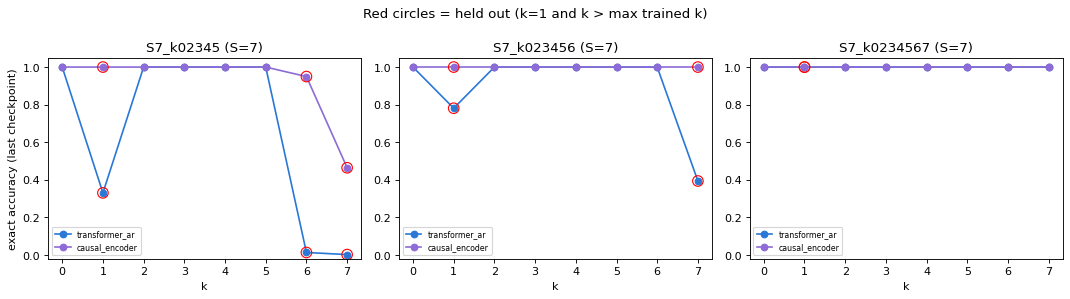

REVIEW FILE: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_partb/S7_Sweep_20k_partb_Review.ipynb
REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_partb/S7_Sweep_20k_partb_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
# --- Report for THIS half + review export (reads saved artifacts only) ---------------------------------------------
rp = LX.report(RESULTS_ROOT, MODE, SEED, conditions=RUN_CONDITIONS, subdir=SUBDIR, out_name=f"seed_{SEED}_partb",
               title_note=f"Budget: {STEPS} updates; sampled evaluation {EVAL_PLAN}. Part b of 2.",
               review_name="S7_Sweep_20k_partb_Review.ipynb")
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB:
    from google.colab import files
    files.download(str(rp))


# Transformer AR vs causal encoder — LAST checkpoint, singletons and longer instructions (seed 42)
12/12 runs complete. Every number below is for the model after the final update (not the validation-selected checkpoint). Budget: 20000 updates; sampled evaluation {'n_single_grids': 1000, 'n_seen_per_k': 5000, 'n_long_per_k': 20000}. All 12 runs.


### Run status (first 10 of 12 rows; full table in CSV export)


,condition,model,trained,evaluated_last,records,best_step (reference),complete
0,S7_k02,transformer_ar,True,True,127000,19250,True
1,S7_k02,causal_encoder,True,True,127000,11000,True
2,S7_k023,transformer_ar,True,True,112000,12750,True
3,S7_k023,causal_encoder,True,True,112000,9250,True
4,S7_k0234,transformer_ar,True,True,97000,17750,True
5,S7_k0234,causal_encoder,True,True,97000,20000,True
6,S7_k02345,transformer_ar,True,True,82000,20000,True
7,S7_k02345,causal_encoder,True,True,82000,19500,True
8,S7_k023456,transformer_ar,True,True,67000,19500,True
9,S7_k023456,causal_encoder,True,True,67000,20000,True



### Summary: singletons and longer held-out instructions (LAST checkpoint)


,condition,model,status,A,B,C,singletons,singleton cell acc,trained-k exact,k=3 exact,k=4 exact,k=5 exact,k=6 exact,k=7 exact
0,S7_k02,transformer_ar,available,0/7000,0/7000,0/7000,0/21000,0.0997,1.0000,0/20000 (0.000),1484/20000 (0.074),0/20000 (0.000),545/20000 (0.027),0/20000 (0.000)
1,S7_k02,causal_encoder,available,0/7000,0/7000,0/7000,0/21000,0.0997,1.0000,0/20000 (0.000),1496/20000 (0.075),0/20000 (0.000),474/20000 (0.024),0/20000 (0.000)
2,S7_k023,transformer_ar,available,0/7000,0/7000,0/7000,0/21000,0.1068,1.0000,NaN,0/20000 (0.000),0/20000 (0.000),0/20000 (0.000),0/20000 (0.000)
3,S7_k023,causal_encoder,available,0/7000,0/7000,0/7000,0/21000,0.1427,1.0000,NaN,0/20000 (0.000),77/20000 (0.004),0/20000 (0.000),0/20000 (0.000)
4,S7_k0234,transformer_ar,available,0/7000,5903/7000,0/7000,5903/21000,0.3978,1.0000,NaN,NaN,0/20000 (0.000),1094/20000 (0.055),0/20000 (0.000)
5,S7_k0234,causal_encoder,available,0/7000,0/7000,0/7000,0/21000,0.2099,1.0000,NaN,NaN,0/20000 (0.000),5/20000 (0.000),0/20000 (0.000)
6,S7_k02345,transformer_ar,available,0/7000,6941/7000,0/7000,6941/21000,0.4103,1.0000,NaN,NaN,NaN,271/20000 (0.014),47/20000 (0.002)
7,S7_k02345,causal_encoder,available,7000/7000,7000/7000,7000/7000,21000/21000,1.0000,1.0000,NaN,NaN,NaN,18990/20000 (0.950),9284/20000 (0.464)
8,S7_k023456,transformer_ar,available,7000/7000,6999/7000,2402/7000,16401/21000,0.8111,0.9999,NaN,NaN,NaN,NaN,7876/20000 (0.394)
9,S7_k023456,causal_encoder,available,7000/7000,7000/7000,7000/7000,21000/21000,1.0000,1.0000,NaN,NaN,NaN,NaN,20000/20000 (1.000)



### Exact / cell accuracy by k


... (4 outputs left out)

,condition,model,op,n,correct,identity copy,other legal transform,non-legal grid
0,S7_k02,transformer_ar,A,7000,0,0,6920,80
1,S7_k02,transformer_ar,B,7000,0,0,6998,2
2,S7_k02,transformer_ar,C,7000,0,7000,0,0
3,S7_k02,causal_encoder,A,7000,0,0,7000,0
4,S7_k02,causal_encoder,B,7000,0,0,7000,0
5,S7_k02,causal_encoder,C,7000,0,7000,0,0
6,S7_k023,transformer_ar,A,7000,0,0,1170,5830
7,S7_k023,transformer_ar,B,7000,0,0,1051,5949
8,S7_k023,transformer_ar,C,7000,0,7000,0,0
9,S7_k023,causal_encoder,A,7000,0,5,0,6995



### AR vs causal encoder on identical test records


,condition,k,n,AR correct,causal enc correct,both,only AR,only causal enc,neither
0,S7_k02,0,1000,1000,1000,1000,0,0,0
1,S7_k02,1,21000,0,0,0,0,0,21000
2,S7_k02,2,5000,5000,5000,5000,0,0,0
3,S7_k02,3,20000,0,0,0,0,0,20000
4,S7_k02,4,20000,1484,1496,1239,245,257,18259
5,S7_k02,5,20000,0,0,0,0,0,20000
6,S7_k02,6,20000,545,474,336,209,138,19317
7,S7_k02,7,20000,0,0,0,0,0,20000
8,S7_k023,0,1000,1000,1000,1000,0,0,0
9,S7_k023,1,21000,0,0,0,0,0,21000



### Exact accuracy by k


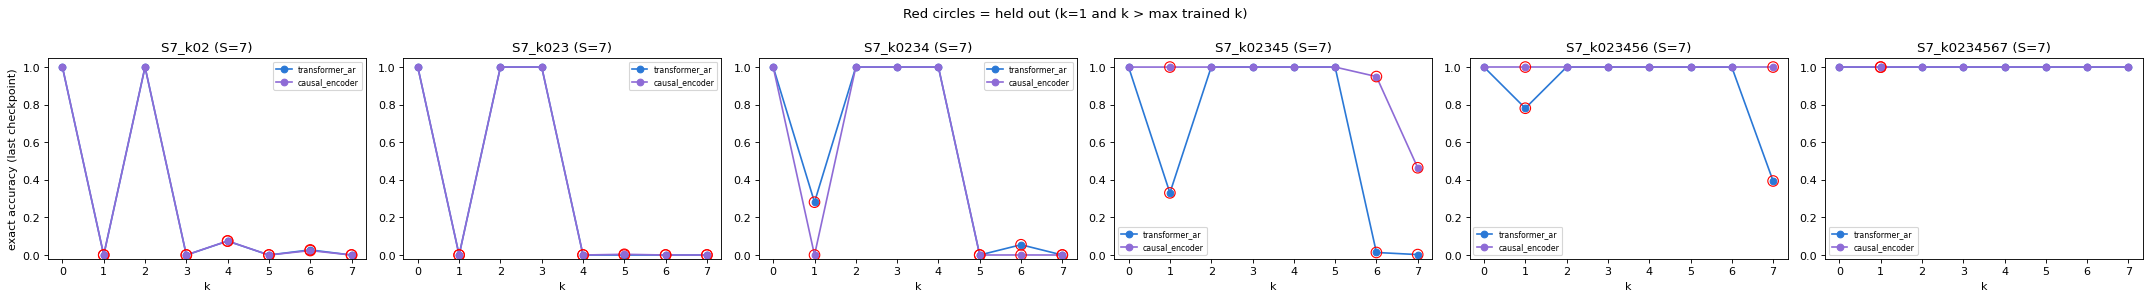

REVIEW FILE: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_all/S7_Sweep_20k_ALL_Review.ipynb
COMBINED REVIEW FILE: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_all/S7_Sweep_20k_ALL_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# --- OPTIONAL: combined report for ALL 6 conditions (run after BOTH notebooks 23a and 23b have finished) ---------
rp_all = LX.report(RESULTS_ROOT, MODE, SEED, conditions=ALL_CONDITIONS, subdir=SUBDIR, out_name=f"seed_{SEED}_all",
                   title_note=f"Budget: {STEPS} updates; sampled evaluation {EVAL_PLAN}. All 12 runs.",
                   review_name="S7_Sweep_20k_ALL_Review.ipynb")
print("COMBINED REVIEW FILE:", rp_all)
if IN_COLAB:
    from google.colab import files
    files.download(str(rp_all))
